# Lesson 2 — ML for Occupancy & Space Usage
### From sensor streams to a first model

**Smarter Campus · Creativity, Science and Innovation · Politecnico di Milano**

We follow the pipeline of the lesson, step by step, on one study room:

**Part 1 (sections 1–7), after the slides on feature selection**
1. load the data and **look** at it
2. **clean** it (lesson 1: missing values and outliers)
3. check the **labels**: is the timetable a good label?
4. cut the streams into **windows** and extract **features**
5. look at the **correlations**
6. how we evaluate: **leave-one-day-out**
7. **select** the features

**Part 2 (sections 8–11), after the slides on evaluation**
8. **classification**: free, occupied or crowded?
9. **regression**: how many people?
10. why a **random split** is misleading
11. when a tree starts to **overfit**

**The dataset** (`study_room_dataset.csv`) is **simulated** for this course: a study room with 40 seats, two weeks of weekdays, 07:00–21:00, one reading per minute.

| column | meaning |
|---|---|
| `timestamp` | date and time (one row per minute) |
| `co2_ppm` | CO₂ in parts per million |
| `pir_triggers` | motion events counted in the minute |
| `noise_db` | average sound level in the minute (dB) |
| `people` | real number of people (ground truth) |
| `lesson_scheduled` | 1 if the timetable says a lesson is booked in the room |

Like real data, it has problems: lost readings, a 25-minute Wi-Fi outage, a few outliers, and two booked lessons that did not take place.

In [1]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [2]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import LeaveOneGroupOut, KFold, cross_val_predict, cross_val_score, cross_validate
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, mean_absolute_error, make_scorer

plt.rcParams['figure.figsize'] = (12, 4)
RANDOM_STATE = 0
TEAL, ORANGE, GREY = '#5A8487', '#E8873A', '#9AA5AB'

## 1. Load the data and look at it

In [3]:
# Define your desired path
path = ''

# Change the current working directory to the new path
os.chdir(path)

# Verify the current working directory
print("Current Working Directory:", os.getcwd())

Current Working Directory: /content/drive/My Drive/CSI_smartcampus26


In [4]:
df = pd.read_csv('study_room_dataset.csv', parse_dates=['timestamp'])
df['day'] = df['timestamp'].dt.date.astype(str)
print(df.shape, '- from', df['timestamp'].min(), 'to', df['timestamp'].max())
df.head()

(8400, 7) - from 2026-10-05 07:00:00 to 2026-10-16 20:59:00


,timestamp,co2_ppm,pir_triggers,noise_db,people,lesson_scheduled,day
0,2026-10-05 07:00:00,420.0,0.0,38.2,0,0,2026-10-05
1,2026-10-05 07:01:00,417.0,0.0,31.8,0,0,2026-10-05
2,2026-10-05 07:02:00,416.0,0.0,36.4,0,0,2026-10-05
3,2026-10-05 07:03:00,419.0,0.0,34.5,0,0,2026-10-05
4,2026-10-05 07:04:00,417.0,0.0,34.8,0,0,2026-10-05


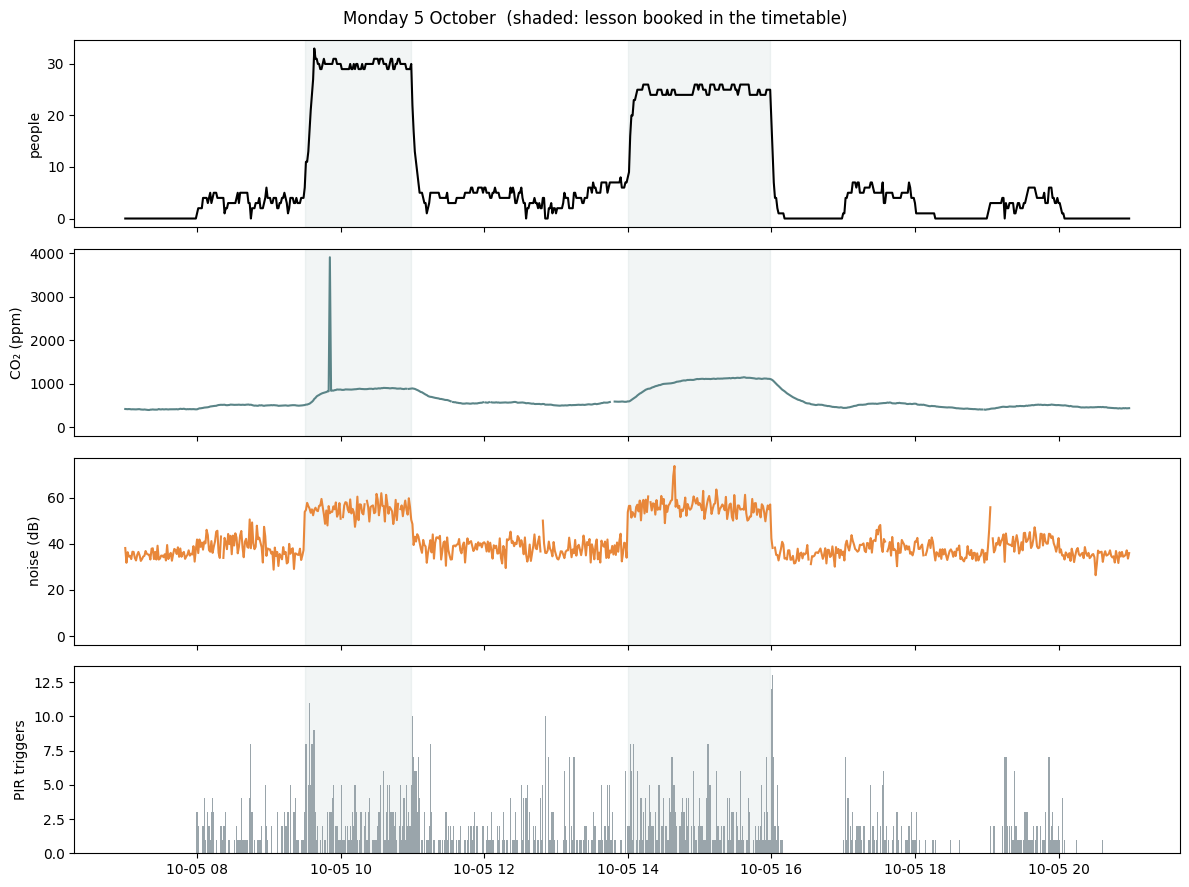

In [5]:
def plot_day(d, title):
    fig, ax = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
    for a in ax:
        a.fill_between(d['timestamp'], 0, 1, where=d['lesson_scheduled'] == 1, color=TEAL, alpha=0.08,
                       transform=a.get_xaxis_transform())
    ax[0].plot(d['timestamp'], d['people'], color='black'); ax[0].set_ylabel('people')
    ax[1].plot(d['timestamp'], d['co2_ppm'], color=TEAL); ax[1].set_ylabel('CO₂ (ppm)')
    ax[2].plot(d['timestamp'], d['noise_db'], color=ORANGE); ax[2].set_ylabel('noise (dB)')
    ax[3].bar(d['timestamp'], d['pir_triggers'], width=1/1440, color=GREY); ax[3].set_ylabel('PIR triggers')
    fig.suptitle(title + '  (shaded: lesson booked in the timetable)'); plt.tight_layout(); plt.show()

plot_day(df[df['day'] == '2026-10-05'], 'Monday 5 October')

**Questions for the class**
- Which signal follows the number of people best? Which one reacts first, which one is slow?
- Why does CO₂ keep going down for almost an hour after the lesson ends?
- Do you see readings that look wrong?

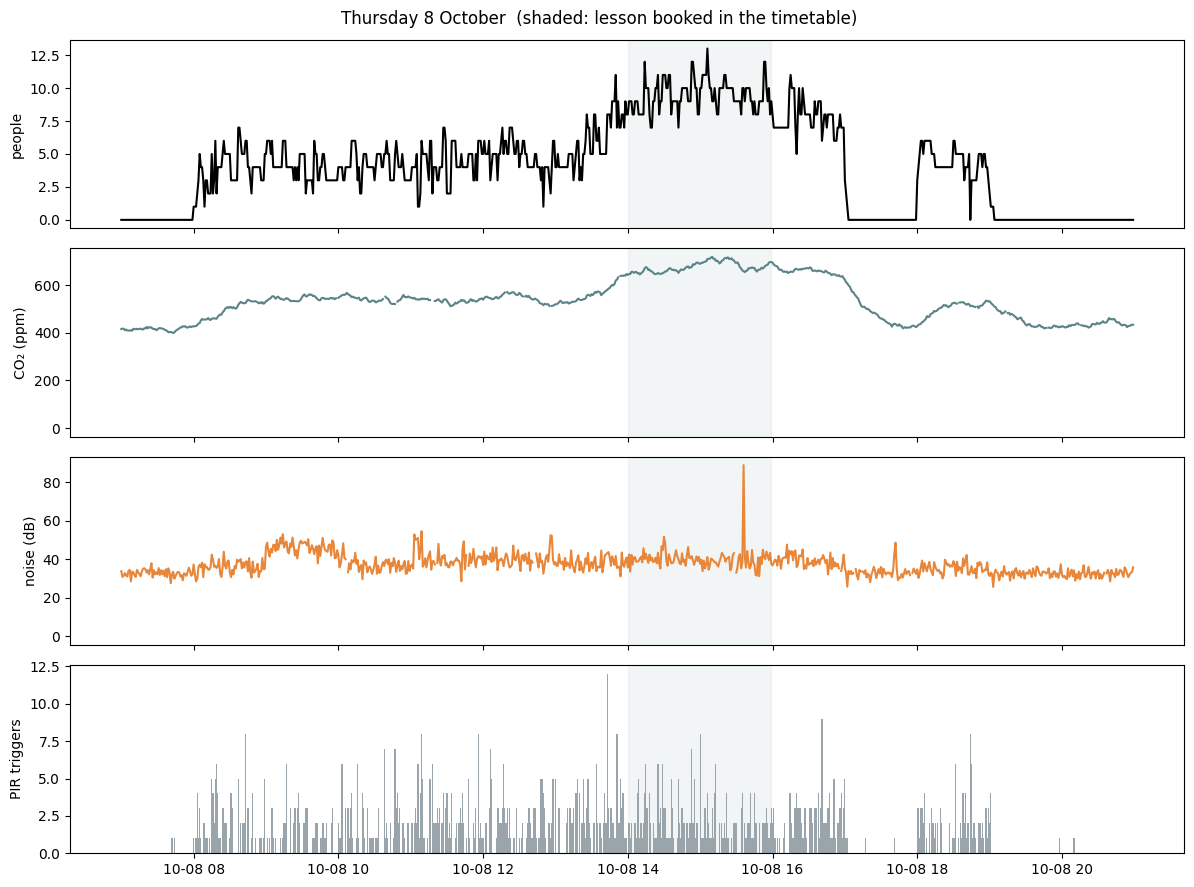

In [6]:
plot_day(df[df['day'] == '2026-10-08'], 'Thursday 8 October')

Look at the afternoon of 8 October: a lesson is **booked**, but the room is not full. Keep it in mind for the labels.

## 2. Clean the data (lesson 1)

First, **outliers**. A global threshold would also cut the real CO₂ peaks of the lessons (try it!). Here we use a *local* rule: a reading is an outlier if it is far from the **median of the 5 minutes around it** (more than 300 ppm for CO₂, 20 dB for noise). Outliers become missing.

Then **missing values**: forward fill, but only for short gaps (up to 5 minutes). Longer gaps stay missing.

In [7]:
SIGNALS = ['co2_ppm', 'pir_triggers', 'noise_db']
print('Missing values before cleaning:'); print(df[SIGNALS].isna().sum())

clean = df.copy()
for c, limit in [('co2_ppm', 300), ('noise_db', 20)]:
    local_median = clean.groupby('day')[c].transform(lambda s: s.rolling(5, center=True, min_periods=3).median())
    outlier = (clean[c] - local_median).abs() > limit
    print(f'{c}: {outlier.sum()} outliers removed')
    clean.loc[outlier, c] = np.nan
clean[SIGNALS] = clean.groupby('day')[SIGNALS].ffill(limit=5)
print('Missing values after cleaning:'); print(clean[SIGNALS].isna().sum())

Missing values before cleaning:
co2_ppm         105
pir_triggers    114
noise_db        113
dtype: int64
co2_ppm: 4 outliers removed
noise_db: 3 outliers removed
Missing values after cleaning:
co2_ppm         20
pir_triggers    20
noise_db        20
dtype: int64


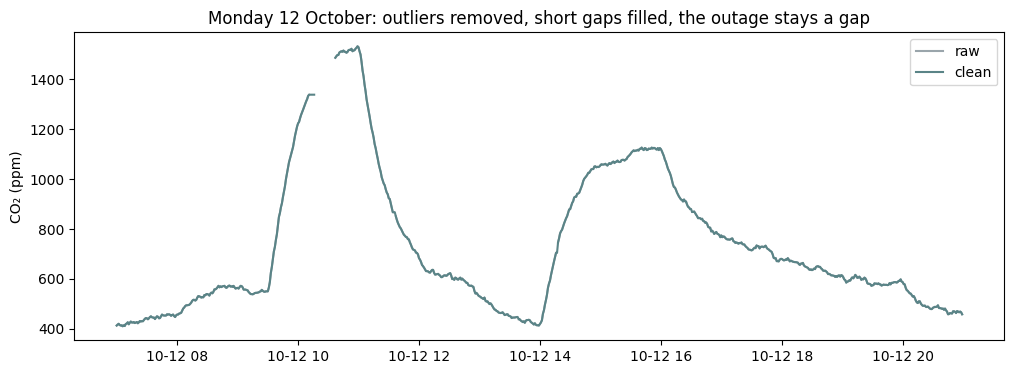

In [8]:
# Before and after, on the day with the Wi-Fi outage
d0, d1 = df[df['day'] == '2026-10-12'], clean[clean['day'] == '2026-10-12']
plt.plot(d0['timestamp'], d0['co2_ppm'], color=GREY, label='raw')
plt.plot(d1['timestamp'], d1['co2_ppm'], color=TEAL, label='clean')
plt.ylabel('CO₂ (ppm)'); plt.legend(); plt.title('Monday 12 October: outliers removed, short gaps filled, the outage stays a gap'); plt.show()

## 3. The labels: is the timetable good enough?

Counting people by hand is expensive. Could we use the **timetable** as a label instead (*lesson booked → room occupied*)?
Here we can check, because we have the real count.

In [9]:
STATES = ['free', 'occupied', 'crowded']
def to_state(n):
    return 0 if n == 0 else (1 if n < 25 else 2)        # crowded = 25 people or more (40 seats)

clean['state'] = clean['people'].map(to_state)
pd.crosstab(clean['lesson_scheduled'].map({0: 'no lesson booked', 1: 'lesson booked'}),
            clean['state'].map(dict(enumerate(STATES))), normalize='index').round(2)

state,crowded,free,occupied
lesson_scheduled,,,
lesson booked,0.35,0.00,0.65
no lesson booked,0.00,0.32,0.68


**Questions for the class**
- When a lesson is booked, how often is the room really crowded?
- When no lesson is booked, is the room free? What does the timetable miss completely?
- So: the timetable is a **weak label**. Useful as a feature or as a first guess, not as ground truth.

## 4. From streams to windows, from windows to features

- **window:** 10 minutes = 10 readings; **step:** 5 minutes (consecutive windows overlap)
- a window with more than 2 missing readings is skipped (e.g., the Wi-Fi outage)
- the label of a window: the most frequent state (classification) and the average number of people (regression)

In [10]:
WINDOW, STEP = 10, 5

def features(win):
    minutes = np.arange(len(win))
    co2 = win['co2_ppm'].interpolate(limit_direction='both')
    return {
        'start': win['timestamp'].iloc[0],
        'day': win['day'].iloc[0],
        'co2_mean': co2.mean(),
        'co2_std': co2.std(),
        'co2_slope': np.polyfit(minutes, co2, 1)[0],          # ppm per minute
        'pir_count': win['pir_triggers'].sum(),
        'noise_mean': win['noise_db'].mean(),
        'noise_std': win['noise_db'].std(),
        'noise_p2p': win['noise_db'].max() - win['noise_db'].min(),
        'lesson_scheduled': win['lesson_scheduled'].max(),      # context from the timetable
        'state': win['state'].mode().iloc[0],
        'people': win['people'].mean(),
    }

rows = []
for _, d in clean.groupby('day'):
    for i in range(0, len(d) - WINDOW + 1, STEP):
        win = d.iloc[i:i + WINDOW]
        if win[SIGNALS].isna().any(axis=1).sum() <= 2:
            rows.append(features(win))
W = pd.DataFrame(rows)
print(len(W), 'windows')
W.head()

1665 windows


,start,day,co2_mean,co2_std,co2_slope,pir_count,noise_mean,noise_std,noise_p2p,lesson_scheduled,state,people
0,2026-10-05 07:00:00,2026-10-05,415.1,3.142893,-0.915152,0.0,34.89,2.000805,6.4,0,0,0.0
1,2026-10-05 07:05:00,2026-10-05,412.3,3.093003,-0.357576,0.0,34.59,1.575824,4.0,0,0,0.0
2,2026-10-05 07:10:00,2026-10-05,407.7,6.395311,-1.933333,0.0,35.00,1.297861,4.3,0,0,0.0
3,2026-10-05 07:15:00,2026-10-05,404.0,4.496913,0.230303,0.0,35.52,1.691679,4.9,0,0,0.0
4,2026-10-05 07:20:00,2026-10-05,407.1,5.606544,1.290909,0.0,35.36,2.379169,6.0,0,0,0.0


In [11]:
# Windows per class: is the dataset balanced?
W['state'].map(dict(enumerate(STATES))).value_counts()

,count
state,
occupied,1130
free,438
crowded,97


## 5. Correlation between features

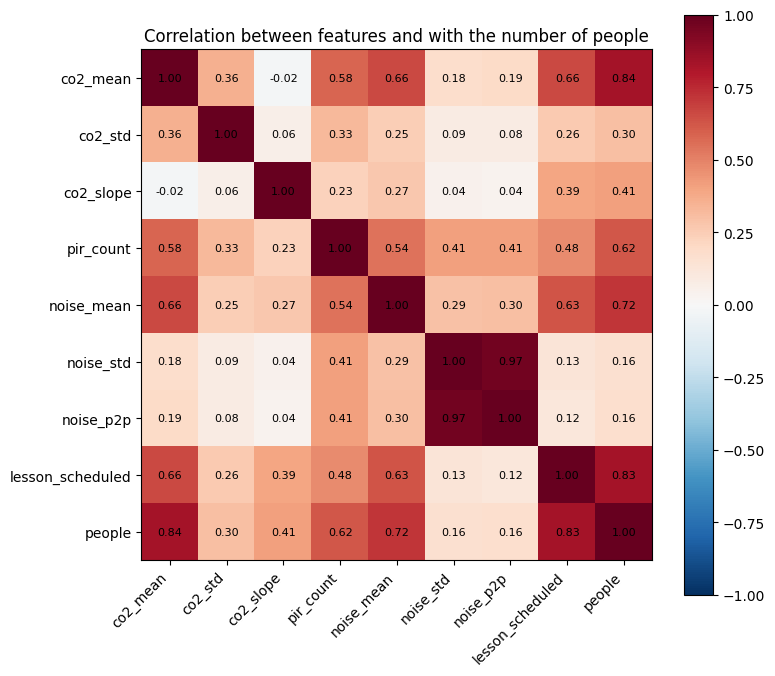

In [12]:
FEATURES = ['co2_mean', 'co2_std', 'co2_slope', 'pir_count', 'noise_mean', 'noise_std', 'noise_p2p', 'lesson_scheduled']
corr = W[FEATURES + ['people']].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im); ax.set_title('Correlation between features and with the number of people')
plt.tight_layout(); plt.show()

**Questions for the class**
- Which features carry almost the same information? Do we need both?
- `co2_slope` is weakly correlated with `people`. Is it useless? (Hint: it says whether people are *arriving* or *leaving*, not how many there are.)

## 6. How we evaluate: leave-one-day-out

Every fold is a **full day** the model has never seen: train on the other days, test on the day left out. (Why not a random split? See section 10.)

In [13]:
X, y_state, y_people, days = W[FEATURES], W['state'], W['people'], W['day']
splits = list(LeaveOneGroupOut().split(X, y_state, groups=days))
print(len(splits), 'folds (one per day)')

10 folds (one per day)


## 7. Feature selection (forward)

Start with no features; at each step add the one that improves the score the most; stop when the gain is below `tol`.

In [14]:
tree = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
F1 = make_scorer(f1_score, average='macro', labels=[0, 1, 2], zero_division=0)   # always score all three classes
sfs = SequentialFeatureSelector(tree, direction='forward', n_features_to_select='auto', tol=0.01,
                                scoring=F1, cv=splits)
sfs.fit(X, y_state)
SELECTED = [str(f) for f in np.array(FEATURES)[sfs.get_support()]]
print('Forward selection keeps:', SELECTED)

Forward selection keeps: ['co2_mean', 'co2_slope', 'pir_count']


# Part 2
## 8. Classification: free, occupied or crowded?

Baseline (always the most frequent class): macro F1 = 0.27
Decision tree:                              macro F1 = 0.75

              precision    recall  f1-score   support

        free       0.97      0.92      0.94       438
    occupied       0.91      0.97      0.94      1130
     crowded       0.51      0.30      0.38        97

    accuracy                           0.91      1665
   macro avg       0.80      0.73      0.75      1665
weighted avg       0.91      0.91      0.91      1665



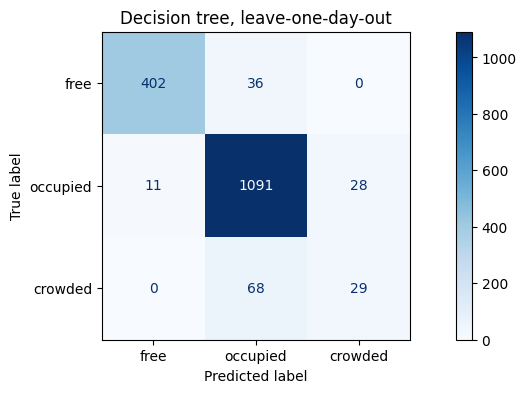

In [15]:
baseline = cross_val_predict(DummyClassifier(strategy='most_frequent'), X, y_state, cv=splits)
pred = cross_val_predict(tree, W[SELECTED], y_state, cv=splits)
print(f"Baseline (always the most frequent class): macro F1 = {f1_score(y_state, baseline, average='macro'):.2f}")
print(f"Decision tree:                              macro F1 = {f1_score(y_state, pred, average='macro'):.2f}\n")
print(classification_report(y_state, pred, target_names=STATES))
ConfusionMatrixDisplay.from_predictions(y_state, pred, display_labels=STATES, cmap='Blues')
plt.title('Decision tree, leave-one-day-out'); plt.show()

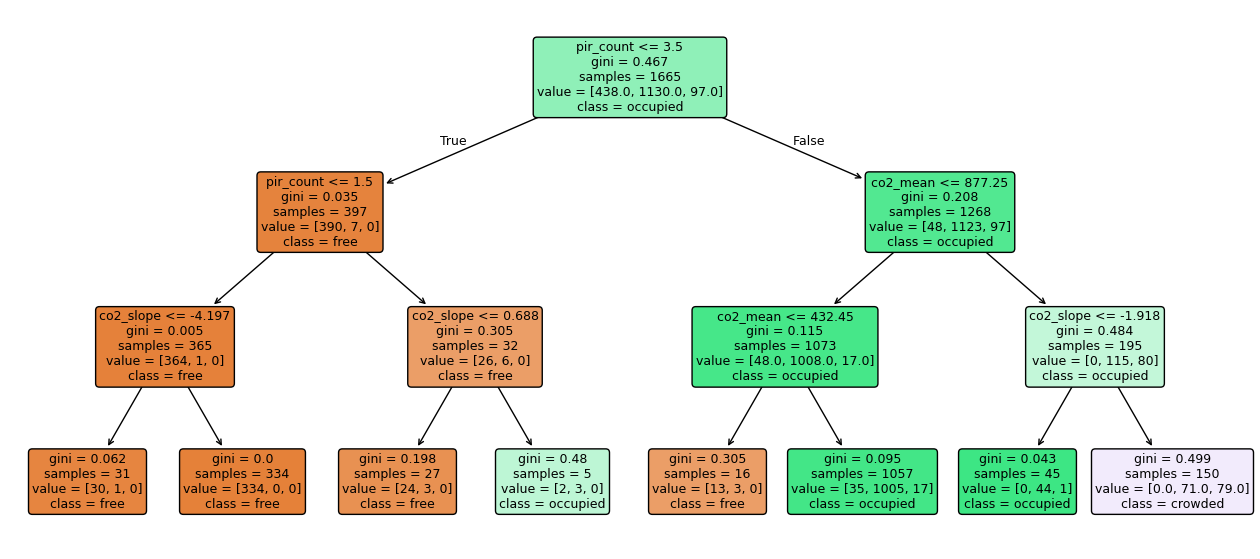

In [16]:
# The tree trained on all days: rules you can read, and run on a board
small = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(W[SELECTED], y_state)
plt.figure(figsize=(16, 7))
plot_tree(small, feature_names=SELECTED, class_names=STATES, filled=True, rounded=True, fontsize=9); plt.show()

## 9. Regression: how many people?

Linear regression: mean absolute error = 1.8 people
Decision tree: mean absolute error = 1.8 people


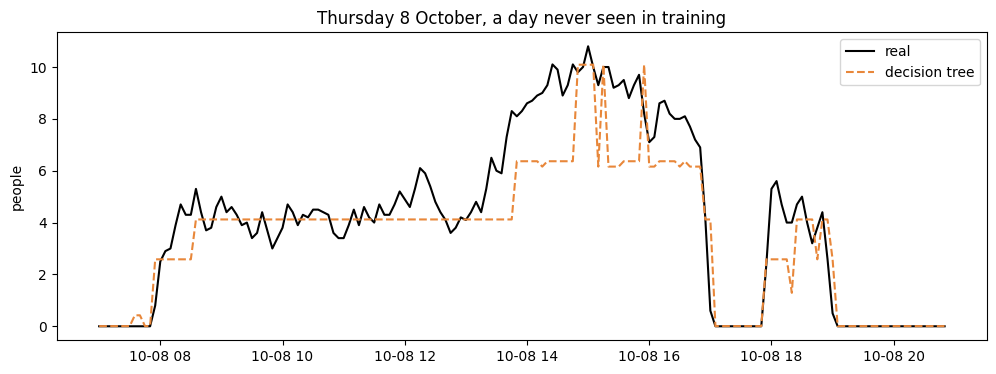

In [17]:
reg_pred = {}
for name, model in [('Linear regression', LinearRegression()),
                    ('Decision tree', DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE))]:
    reg_pred[name] = cross_val_predict(model, W[SELECTED], y_people, cv=splits)
    print(f'{name}: mean absolute error = {mean_absolute_error(y_people, reg_pred[name]):.1f} people')

one = W['day'] == '2026-10-08'
plt.plot(W.loc[one, 'start'], y_people[one], color='black', label='real')
plt.plot(W.loc[one, 'start'], reg_pred['Decision tree'][one], '--', color=ORANGE, label='decision tree')
plt.ylabel('people'); plt.legend(); plt.title('Thursday 8 October, a day never seen in training'); plt.show()

## 10. Why we don't shuffle

In [18]:
shuffled = cross_val_predict(tree, W[SELECTED], y_state, cv=KFold(10, shuffle=True, random_state=RANDOM_STATE))
by_day = cross_val_predict(tree, W[SELECTED], y_state, cv=splits)
print(f"Random split (10 folds): macro F1 = {f1_score(y_state, shuffled, average='macro'):.3f}")
print(f"Leave-one-day-out:       macro F1 = {f1_score(y_state, by_day, average='macro'):.3f}")

Random split (10 folds): macro F1 = 0.790
Leave-one-day-out:       macro F1 = 0.753


Windows at 10:00 and 10:05 share half of their readings. With a random split one ends up in training and the other in test: the model partly **remembers** instead of generalizing, and the score looks better than it will be on a new day.

## 11. Overfitting: how deep should the tree be?

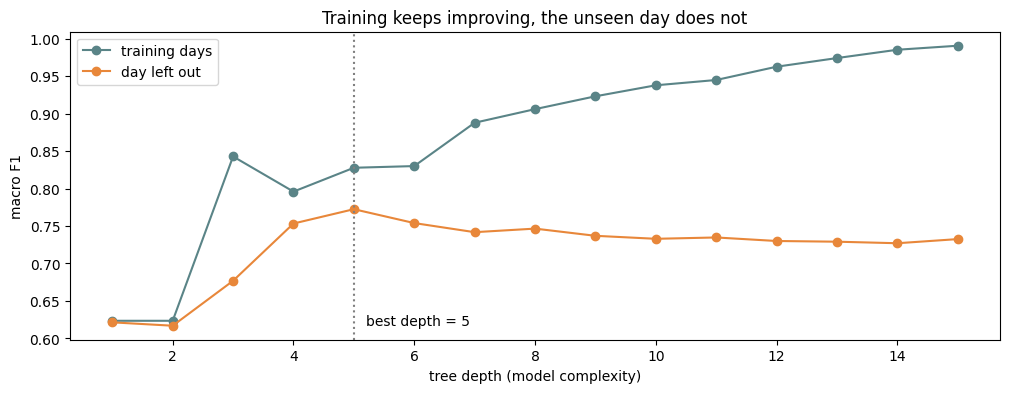

In [19]:
depths = range(1, 16)
train_f1, test_f1 = [], []
for d in depths:
    model = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    Xs = W[SELECTED]
    train_f1.append(f1_score(y_state, model.fit(Xs, y_state).predict(Xs), average='macro'))          # on the days it has seen
    test_f1.append(f1_score(y_state, cross_val_predict(model, Xs, y_state, cv=splits), average='macro'))  # on days left out
plt.plot(depths, train_f1, 'o-', color=TEAL, label='training days')
plt.plot(depths, test_f1, 'o-', color=ORANGE, label='day left out')
best = depths[int(np.argmax(test_f1))]
plt.axvline(best, ls=':', color='grey'); plt.text(best + 0.2, min(test_f1), f'best depth = {best}')
plt.xlabel('tree depth (model complexity)'); plt.ylabel('macro F1'); plt.legend()
plt.title('Training keeps improving, the unseen day does not'); plt.show()

## Try it yourself
- change `WINDOW` and `STEP` (e.g., 5 or 20 minutes): what changes?
- remove `lesson_scheduled` from the features: how much do you lose?
- try a `RandomForestClassifier`, or an `SVC` (scale the features first)
- **your project:** which of these features can you compute with the sensors on your Arduino UNO Q?